# Eksperimen MovieLens-1M: Cold-to-Warm Threshold
Replikasi skala kecil dari *Recommendation Is a Dish Better Served Warm* (Gusak dkk., RecSys 2025).

| | Paper | Notebook ini |
|---|---|---|
| Dataset | ML-1M, BeerAdvocate, Behance, Amazon Beauty | ML-1M |
| Model | EASE^R, PureSVD, ItemKNN, SASRec-CE | ItemKNN, EASE^R |
| User-Based | semua user test | sama |
| Item-Based | S = 1000 item, successive evaluation penuh | S lebih kecil, maks. 3 langkah successive, maks. 500 user test (karena komputasi) |
| Tuning | 20 titik acak dari grid | grid kecil penuh |
| Lebar sliding window | tidak disebutkan | 3 titik (**asumsi**) |

Data: unduh `ml-1m.zip` dari https://grouplens.org/datasets/movielens/1m/ lalu ekstrak ke `data/raw/ml-1m/`.

In [1]:
import sys, time; sys.path.insert(0, "../src")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import coldwarm as cw
pd.set_option("display.precision", 4)
RUN_ITEM_BASED = True     # ±15-30 menit; set False kalau hanya butuh User-Based
ITEM_S = 50               # jumlah item sampel (paper: 1000)

## 1. Input & statistik (bandingkan dengan Table 1 paper)

In [2]:
df = cw.load_ml1m("../data/raw/ml-1m/ratings.dat")
df, n_users, n_items = cw.encode(df)
stats = dict(users=n_users, items=n_items, interactions=len(df),
             density=f"{len(df)/(n_users*n_items):.2%}",
             avg_user=round(len(df)/n_users), avg_item=round(len(df)/n_items))
print(stats)
print("Paper: 6,040 user, 3,706 item, 1,000,209 interaksi, density 4.47%, avg user 166, avg item 270")

{'users': 6040, 'items': 3706, 'interactions': 1000209, 'density': '4.47%', 'avg_user': 166, 'avg_item': 270}
Paper: 6,040 user, 3,706 item, 1,000,209 interaksi, density 4.47%, avg user 166, avg item 270


## 2. Preprocessing: split global timepoint (kuantil 0.9)

In [3]:
split = cw.global_timepoint_split(df, q=0.9, val_frac=0.1, include_test_history_in_train=True, seed=0)
print("GT timestamp:", pd.to_datetime(split.gt_time, unit="s"))
print("interaksi train:", len(split.train), "| user valid:", len(split.val_hist), "| user test:", len(split.test_hist))
X = cw.to_matrix(split.train, n_users, n_items)

GT timestamp: 2000-12-29 23:42:56.399999976
interaksi train: 836101 | user valid: 483 | user test: 1180


## 3. Tuning hyperparameter di set validasi (NDCG@10)

In [4]:
t = time.time()
knn_params, knn_res = cw.tune(cw.ItemKNN, [dict(k=k, shrink=s) for k in (10, 25, 50, 100, 200, 400) for s in (0, 10, 50)],
                              X, split, n_items)
ease_params, ease_res = cw.tune(cw.EASE, [dict(lam=l) for l in (50, 100, 200, 500, 1000, 2000, 5000)], X, split, n_items)
print("ItemKNN terbaik:", knn_params, "| EASE terbaik:", ease_params, f"| {time.time()-t:.0f}s")
pd.DataFrame([{**p, "NDCG@10": v} for p, v in knn_res]).sort_values("NDCG@10", ascending=False).head()

ItemKNN terbaik: {'k': 400, 'shrink': 50} | EASE terbaik: {'lam': 200} | 51s


,k,shrink,NDCG@10
17,400,50,0.0453
15,400,0,0.0428
16,400,10,0.0413
13,200,10,0.0409
12,200,0,0.0401


## 4. Contoh output rekomendasi
Contoh rekomendasi top-10 untuk satu user test, memakai riwayat lengkap sebelum GT.

In [5]:
movies = pd.read_csv("../data/raw/ml-1m/movies.dat", sep="::", engine="python",
                     names=["item_id","title","genres"], encoding="latin-1").set_index("item_id")
item_ids = pd.factorize(cw.load_ml1m("../data/raw/ml-1m/ratings.dat")["item_id"])[1]
title = lambda i: movies.loc[item_ids[i], "title"]
knn = cw.ItemKNN(**knn_params).fit(X)
u = next(iter(split.test_hist))
print("5 tontonan terakhir:", [title(i) for i in split.test_hist[u][-5:]])
print("Ground truth (interaksi pertama setelah GT):", title(split.test_holdout[u][0]))
for r, i in enumerate(cw.recommend(knn, [split.test_hist[u]], n_items, 10)[0], 1):
    print(f"{r:2d}. {title(i)}")

5 tontonan terakhir: ["Wayne's World 2 (1993)", 'Everyone Says I Love You (1996)', "You've Got Mail (1998)", 'Brady Bunch Movie, The (1995)', 'Austin Powers: The Spy Who Shagged Me (1999)']
Ground truth (interaksi pertama setelah GT): Englishman Who Went Up a Hill, But Came Down a Mountain, The (1995)
 1. Groundhog Day (1993)
 2. Forrest Gump (1994)
 3. Star Wars: Episode V - The Empire Strikes Back (1980)
 4. Lethal Weapon (1987)
 5. E.T. the Extra-Terrestrial (1982)
 6. Monty Python and the Holy Grail (1974)
 7. Raiders of the Lost Ark (1981)
 8. Toy Story (1995)
 9. Clueless (1995)
10. Crocodile Dundee (1986)


## 5. User-Based (Sec 3.2)
Model tetap. Riwayat user test di-sample N interaksi (uniform, urutan waktu tetap), lalu HR@10 dan NDCG@10 dihitung terhadap interaksi pertama setelah GT, dirata-rata atas user dengan ≥ N interaksi.

In [6]:
ease = cw.EASE(**ease_params).fit(X)
curves = {"ItemKNN": cw.user_based_curve(knn, split, n_items, seed=0),
          "EASE^R":  cw.user_based_curve(ease, split, n_items, seed=0)}
curves["ItemKNN"]

,N,n_users,HR,HR_ci,NDCG,NDCG_ci
0,1,1180,0.0305,0.0098,0.0160,0.0057
1,2,1180,0.0220,0.0084,0.0110,0.0047
2,3,1178,0.0195,0.0079,0.0100,0.0045
3,4,1176,0.0196,0.0079,0.0087,0.0039
4,5,1175,0.0298,0.0097,0.0127,0.0045
5,6,1158,0.0242,0.0089,0.0090,0.0034
6,7,1147,0.0253,0.0091,0.0109,0.0043
7,8,1134,0.0265,0.0093,0.0106,0.0040
8,10,1120,0.0259,0.0093,0.0108,0.0042
9,12,1108,0.0217,0.0086,0.0090,0.0038


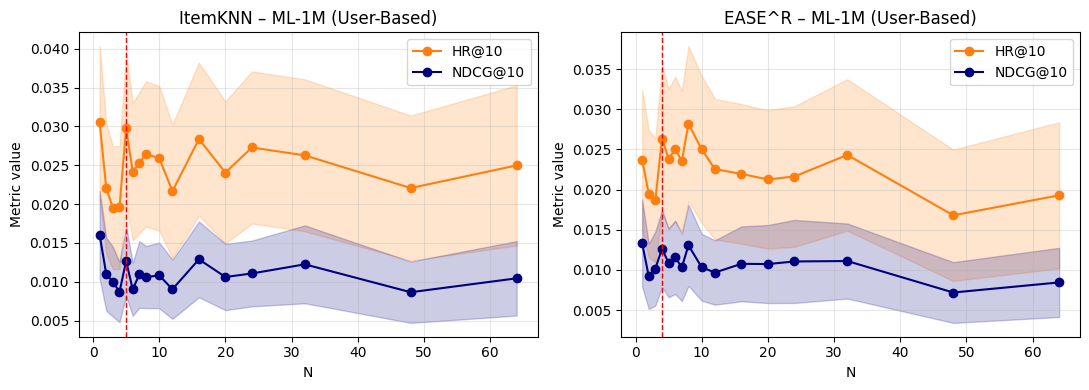

{'ItemKNN': {'HR': 5, 'NDCG': 5}, 'EASE^R': {'HR': 4, 'NDCG': 4}}

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
thr_user = {}
for ax, (name, c) in zip(axes, curves.items()):
    for m, col in (("HR", "tab:orange"), ("NDCG", "navy")):
        ax.plot(c.N, c[m], "o-", color=col, label=f"{m}@10")
        ax.fill_between(c.N, c[m]-c[m+"_ci"], c[m]+c[m+"_ci"], color=col, alpha=.2)
    thr_user[name] = {m: cw.detect_threshold(c.N, c[m])[0] for m in ("HR", "NDCG")}
    if thr_user[name]["NDCG"]: ax.axvline(thr_user[name]["NDCG"], color="red", ls="--", lw=1)
    ax.set(title=f"{name} – ML-1M (User-Based)", xlabel="N", ylabel="Metric value"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig("../results/user_based_ml1m.png", dpi=150); plt.show()
thr_user

## 6. Item-Based (Sec 3.1)
Interaksi user test dikeluarkan dari train. Untuk tiap item sampel dan tiap N: sisakan N interaksi acak, latih ulang, lalu jalankan successive evaluation. Metriknya HR\*@K dan NDCG\*@K (Eq. 1–4).

In [8]:
if RUN_ITEM_BASED:
    split_ib = cw.global_timepoint_split(df, q=0.9, val_frac=0.1, include_test_history_in_train=False, seed=0)
    t = time.time()
    ib_raw = cw.item_based_curve(lambda: cw.ItemKNN(**knn_params), split_ib, n_users, n_items,
                                 n_items_sample=ITEM_S, max_steps=3, max_test_users=500, seed=0, verbose=False)
    ib = cw.aggregate_item_based(ib_raw)
    ib_raw.to_csv("../results/item_based_itemknn_raw.csv", index=False)
    print(f"selesai dalam {(time.time()-t)/60:.1f} menit")
    display(ib[["N", "n_items", "HR*@10", "NDCG*@10", "HR*@100", "NDCG*@100"]])

selesai dalam 20.7 menit


,N,n_items,HR*@10,NDCG*@10,HR*@100,NDCG*@100
0,1,50,0.0,0.0,0.0,0.0
1,2,49,0.0,0.0,0.0,0.0
2,3,49,0.0,0.0,0.0,0.0
3,4,48,0.0,0.0,0.0,0.0
4,5,47,0.0,0.0,0.0,0.0
5,6,47,0.0,0.0,0.0,0.0
6,7,47,0.0,0.0,0.0,0.0
7,8,47,0.0,0.0,0.0,0.0
8,10,44,0.0,0.0,0.0,0.0
9,12,43,0.0,0.0,0.0,0.0


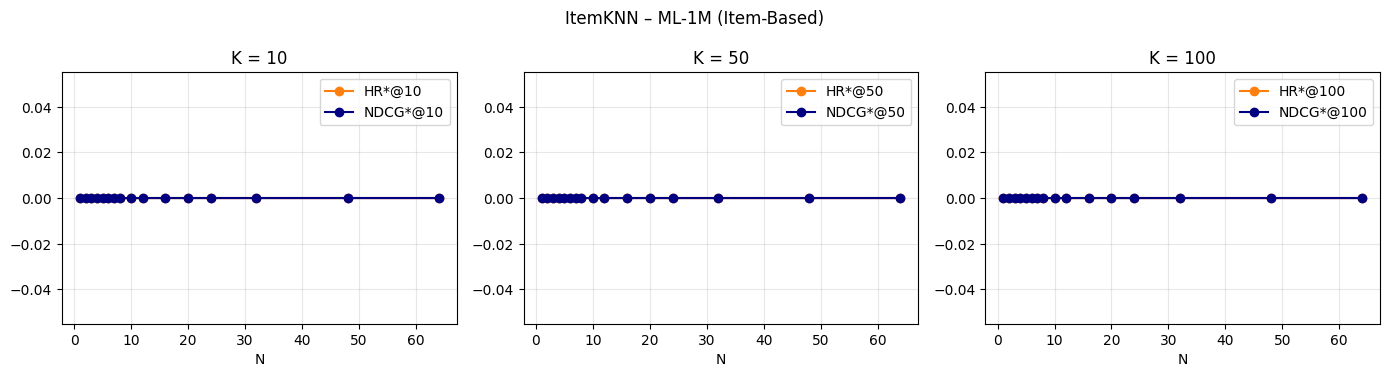

{10: None, 50: None, 100: None}


In [9]:
if RUN_ITEM_BASED:
    fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
    thr_item = {}
    for ax, K in zip(axes, (10, 50, 100)):
        for m, col in ((f"HR*@{K}", "tab:orange"), (f"NDCG*@{K}", "navy")):
            ax.plot(ib.N, ib[m], "o-", color=col, label=m)
            ax.fill_between(ib.N, ib[m]-ib[m+"_ci"], ib[m]+ib[m+"_ci"], color=col, alpha=.2)
        thr_item[K] = cw.detect_threshold(ib.N, ib[f"NDCG*@{K}"])[0]
        if thr_item[K]: ax.axvline(thr_item[K], color="red", ls="--", lw=1)
        ax.set(title=f"K = {K}", xlabel="N"); ax.legend(); ax.grid(alpha=.3)
    plt.suptitle("ItemKNN – ML-1M (Item-Based)"); plt.tight_layout()
    plt.savefig("../results/item_based_ml1m.png", dpi=150); plt.show()
    print(thr_item)

## 7. Ringkasan vs Table 2 paper

In [10]:
rows = [dict(setup="User-Based", model=m, metrik=k, hasil=v,
             paper={"ItemKNN": "4±1.4", "EASE^R": "5±1.1"}[m]) for m, d in thr_user.items() for k, v in d.items()]
if RUN_ITEM_BASED:
    rows += [dict(setup="Item-Based", model="ItemKNN", metrik=f"NDCG*@{K}", hasil=v, paper="9±1.8") for K, v in thr_item.items()]
summary = pd.DataFrame(rows); summary.to_csv("../results/summary.csv", index=False); summary

,setup,model,metrik,hasil,paper
0,User-Based,ItemKNN,HR,5.0,4±1.4
1,User-Based,ItemKNN,NDCG,5.0,4±1.4
2,User-Based,EASE^R,HR,4.0,5±1.1
3,User-Based,EASE^R,NDCG,4.0,5±1.1
4,Item-Based,ItemKNN,NDCG*@10,NaN,9±1.8
5,Item-Based,ItemKNN,NDCG*@50,NaN,9±1.8
6,Item-Based,ItemKNN,NDCG*@100,NaN,9±1.8
